# Embedding & Indexing — Amazon Product Dataset 2020

Covers task backlog §1.3, building on [1.2 process data.ipynb](1.2%20process%20data.ipynb)'s
`products_clean.csv`:

- build embedding text once (`title` + `features`, with fallback)
- embed locally with `sentence-transformers` (free, no API key)
- persist **two** Chroma collections in one shared directory: the `Home & Kitchen` demo
  slice, and the full catalog (all categories)
- sanity-check both with real similarity queries
- visualize the embedding space (PCA + t-SNE, colored by category)

Config-driven via `.env` (see [.env.example](../../.env.example)) — every provider/model/path
below has a code default, so swapping providers later is a config change, not a rewrite.

In [1]:
# !pip install pandas sentence-transformers chromadb python-dotenv scikit-learn matplotlib

## Setup & config

In [2]:
import os

# PyTorch (via sentence-transformers) and scikit-learn each link their own
# copy of the OpenMP runtime; loading both in one process can segfault on
# macOS without this. Must be set before those libraries are imported below.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import pandas as pd
from dotenv import load_dotenv

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
load_dotenv(os.path.join(REPO_ROOT, ".env"))  # no-op if .env doesn't exist

INPUT_CSV = os.path.join(REPO_ROOT, "Code", "data", "processed", "products_clean.csv")

EMBEDDING_PROVIDER = os.environ.get("EMBEDDING_PROVIDER", "sentence-transformers")
EMBEDDING_MODEL = os.environ.get("EMBEDDING_MODEL", "all-MiniLM-L6-v2")
CHROMA_PERSIST_DIR = os.path.join(REPO_ROOT, os.environ.get(
    "CHROMA_PERSIST_DIR", "Code/data/processed/chroma_db"
))
CHROMA_COLLECTION_HK = os.environ.get("CHROMA_COLLECTION", "products_home_kitchen")
CHROMA_COLLECTION_ALL = os.environ.get("CHROMA_COLLECTION_ALL", "products_all")
DEMO_CATEGORY = "Home & Kitchen"

print(f"EMBEDDING_PROVIDER    = {EMBEDDING_PROVIDER}")
print(f"EMBEDDING_MODEL       = {EMBEDDING_MODEL}")
print(f"CHROMA_PERSIST_DIR    = {CHROMA_PERSIST_DIR}")
print(f"CHROMA_COLLECTION_HK  = {CHROMA_COLLECTION_HK}")
print(f"CHROMA_COLLECTION_ALL = {CHROMA_COLLECTION_ALL}")

if EMBEDDING_PROVIDER != "sentence-transformers":
    raise NotImplementedError(
        f"EMBEDDING_PROVIDER={EMBEDDING_PROVIDER!r} is configured but this notebook only "
        "implements the sentence-transformers path so far."
    )

EMBEDDING_PROVIDER    = sentence-transformers
EMBEDDING_MODEL       = all-MiniLM-L6-v2
CHROMA_PERSIST_DIR    = /Users/pareeyaporn/Desktop/ADSP 32028 Applied Generative AI - Agents and Multimodal Intelligence/Project/Code/data/processed/chroma_db
CHROMA_COLLECTION_HK  = products_home_kitchen
CHROMA_COLLECTION_ALL = products_all


In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"

## Load cleaned data & build embedding text

From [1.2 process data.ipynb](1.2%20process%20data.ipynb)'s output — already deduped, brand-
and price-normalized. Embedding text is built once, on the full dataset; category filtering
happens later, per collection.

In [4]:
df = pd.read_csv(INPUT_CSV)
print(f"Loaded {len(df):,} cleaned products (all categories).")


def build_embedding_text(row):
    parts = [row["title"]]
    secondary = row["features"]
    if pd.isna(secondary):
        secondary = row["technical_details"]
    if pd.isna(secondary):
        secondary = row["product_specification"]
    if pd.notna(secondary):
        parts.append(str(secondary))
    return " ".join(parts).strip()


df["embedding_text"] = df.apply(build_embedding_text, axis=1)
before = len(df)
df = df[df["embedding_text"].str.len() > 0].reset_index(drop=True)
print(f"Rows with usable embedding text: {len(df):,} / {before:,}")

Loaded 9,930 cleaned products (all categories).
Rows with usable embedding text: 9,930 / 9,930


## Load the embedding model & compute embeddings

Local, free, no API key (`sentence-transformers` / `all-MiniLM-L6-v2`, 384 dimensions).
Computed **once** for every row — the `Home & Kitchen` collection reuses a slice of these
rather than re-embedding the same products twice.

In [5]:
# Disable HF Hub's widget-based progress bars — they render fine live in Jupyter, but
# leave a broken 'Could not render ...widget-view+json' output once the notebook is
# saved and reopened elsewhere (GitHub, VS Code preview).
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

from sentence_transformers import SentenceTransformer

model = SentenceTransformer(EMBEDDING_MODEL)
print(f"Loaded {EMBEDDING_MODEL}, embedding dimension = {model.get_sentence_embedding_dimension()}")

embeddings = model.encode(df["embedding_text"].tolist(), show_progress_bar=False, batch_size=64)
print(f"Embeddings shape: {embeddings.shape}")

/var/folders/dt/hz0jqyys0fz2ksjdx5kkxm800000gn/T/ipykernel_6968/3759963290.py:9: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Loaded {EMBEDDING_MODEL}, embedding dimension = {model.get_sentence_embedding_dimension()}")


Loaded all-MiniLM-L6-v2, embedding dimension = 384


Embeddings shape: (9930, 384)


## Build/persist both Chroma collections

One shared `CHROMA_PERSIST_DIR`, two named collections — like two tables in one database,
not two separate databases. Idempotent: drops and recreates each collection, then cleans up
orphaned on-disk segment folders (a known Chroma `delete_collection()` gap) so re-running
stays clean on disk too.

In [6]:
import shutil
import sqlite3

import chromadb

METADATA_FIELDS = ["id", "title", "brand", "category_top", "price",
                    "price_per_unit", "price_unit", "url"]


def build_metadata(row):
    meta = {}
    for field in METADATA_FIELDS:
        val = row[field]
        if pd.isna(val):
            continue
        meta[field] = float(val) if isinstance(val, (int, float)) else str(val)
    return meta


os.makedirs(CHROMA_PERSIST_DIR, exist_ok=True)
client = chromadb.PersistentClient(path=CHROMA_PERSIST_DIR)


def build_collection(df_scope, embeddings_scope, collection_name):
    try:
        client.delete_collection(collection_name)
    except Exception:
        pass  # collection didn't exist yet

    collection = client.create_collection(
        name=collection_name,
        metadata={"embedding_model": EMBEDDING_MODEL, "rows": len(df_scope)},
    )
    ids = df_scope["id"].astype(str).tolist()
    metadatas = [build_metadata(row) for _, row in df_scope.iterrows()]
    documents = df_scope["embedding_text"].tolist()

    BATCH_SIZE = 200
    for start in range(0, len(ids), BATCH_SIZE):
        end = start + BATCH_SIZE
        collection.add(
            ids=ids[start:end],
            embeddings=embeddings_scope[start:end].tolist(),
            metadatas=metadatas[start:end],
            documents=documents[start:end],
        )
    print(f"Indexed {collection.count():,} products into collection {collection_name!r}")
    return collection


hk_mask = df["category_top"] == DEMO_CATEGORY
collection_hk = build_collection(df[hk_mask].reset_index(drop=True), embeddings[hk_mask.values],
                                  CHROMA_COLLECTION_HK)
collection_all = build_collection(df, embeddings, CHROMA_COLLECTION_ALL)

print(f"Persisted to: {os.path.relpath(CHROMA_PERSIST_DIR, REPO_ROOT)}")

# Clean up orphaned segment folders left behind by delete_collection() calls above.
sqlite_path = os.path.join(CHROMA_PERSIST_DIR, "chroma.sqlite3")
con = sqlite3.connect(sqlite_path)
live_segment_ids = {row[0] for row in con.execute("SELECT id FROM segments")}
con.close()

removed = [entry for entry in os.listdir(CHROMA_PERSIST_DIR)
           if os.path.isdir(os.path.join(CHROMA_PERSIST_DIR, entry)) and entry not in live_segment_ids]
for entry in removed:
    shutil.rmtree(os.path.join(CHROMA_PERSIST_DIR, entry))
print(f"Removed {len(removed)} orphaned segment folder(s)." if removed
      else "No orphaned segment folders found.")

Indexed 706 products into collection 'products_home_kitchen'


Indexed 9,930 products into collection 'products_all'
Persisted to: Code/data/processed/chroma_db
Removed 2 orphaned segment folder(s).


## Sanity check — query both collections

Real similarity queries against the real indexes, not a claim — read the actual results
below before trusting either collection for anything downstream.

In [7]:
def run_queries(collection, queries, label):
    print(f"--- {label} ---")
    for query in queries:
        query_embedding = model.encode([query])[0].tolist()
        results = collection.query(query_embeddings=[query_embedding], n_results=3)
        print(f"Query: {query!r}")
        for meta, dist in zip(results["metadatas"][0], results["distances"][0]):
            price = meta.get("price")
            price_str = f"${price:.2f}" if price is not None else "?"
            print(f"    [{dist:.3f}] {meta.get('title', '')[:65]}  ({price_str})")
        print()


run_queries(collection_hk, [
    "insulated lunch box for kids",
    "kids bedding set",
], "Home & Kitchen")

run_queries(collection_all, [
    "dinosaur action figure",
    "board game for family night",
], "All categories")

--- Home & Kitchen ---


Query: 'insulated lunch box for kids'
    [0.589] Wildkin Kids Insulated Lunch Box for Boys and Girls, Perfect Size  ($12.77)
    [0.649] Wildkin Kids Insulated Lunch Box for Boys and Girls, Perfect Size  ($10.88)
    [0.687] Wildkin 33600 Monsters Lunch Box, Insulated, Moisture Resistant,   ($14.99)

Query: 'kids bedding set'
    [0.730] Heritage Kids Color Splash Bedding Set, Queen, Pink  ($99.99)
    [0.759] Mi-Zone Kids Dinosaur Dreams Twin Kids Bedding Sets for Boys - Gr  ($54.88)
    [0.787] Urban Habitat Kids Finn Twin/Twin Xl Bedding Sets Boys Quilt Set   ($39.99)

--- All categories ---
Query: 'dinosaur action figure'
    [0.754] Jurassic World Savage Strike Velociraptor Blue  ($7.97)
    [0.775] Fun Express Large PVC Dynamite Dinosaurs - Toys - 12 Pieces  ($5.04)
    [0.795] Family Games America 3D Puzzles - Dinosaurs Puzzle  ($8.32)

Query: 'board game for family night'
    [0.750] Fireside Games Grackles - Board Games for Families - Board Games   ($18.44)
    [0.781] Brain 

## Visualize the embedding space

384 dimensions reduced to 2D with PCA (fast, linear, full dataset) and t-SNE (usually shows
clearer cluster separation, but slow — run on a random sample for speed), colored by category.
Top 7 categories get their own color; everything else folds into "Other", per the project's
categorical-color convention.

In [8]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

CAT_COLORS = {
    "Toys & Games": "#2a78d6",
    "Home & Kitchen": "#eb6834",
    "Clothing, Shoes & Jewelry": "#1baf7a",
    "Sports & Outdoors": "#eda100",
    "Baby Products": "#e87ba4",
    "Arts, Crafts & Sewing": "#008300",
    "Office Products": "#4a3aa7",
}
OTHER_COLOR = "#c3c2c0"

plot_categories = df["category_top"].fillna("(no category)")
plot_colors = plot_categories.map(CAT_COLORS).fillna(OTHER_COLOR)

pca_coords = PCA(n_components=2, random_state=0).fit_transform(embeddings)

TSNE_SAMPLE = 3000
sample_idx = df.sample(n=min(TSNE_SAMPLE, len(df)), random_state=0).index
tsne_coords = TSNE(n_components=2, random_state=0, init="pca").fit_transform(embeddings[sample_idx])

print(f"PCA: {len(df):,} points. t-SNE: {len(sample_idx):,}-point random sample (for speed).")

PCA: 9,930 points. t-SNE: 3,000-point random sample (for speed).


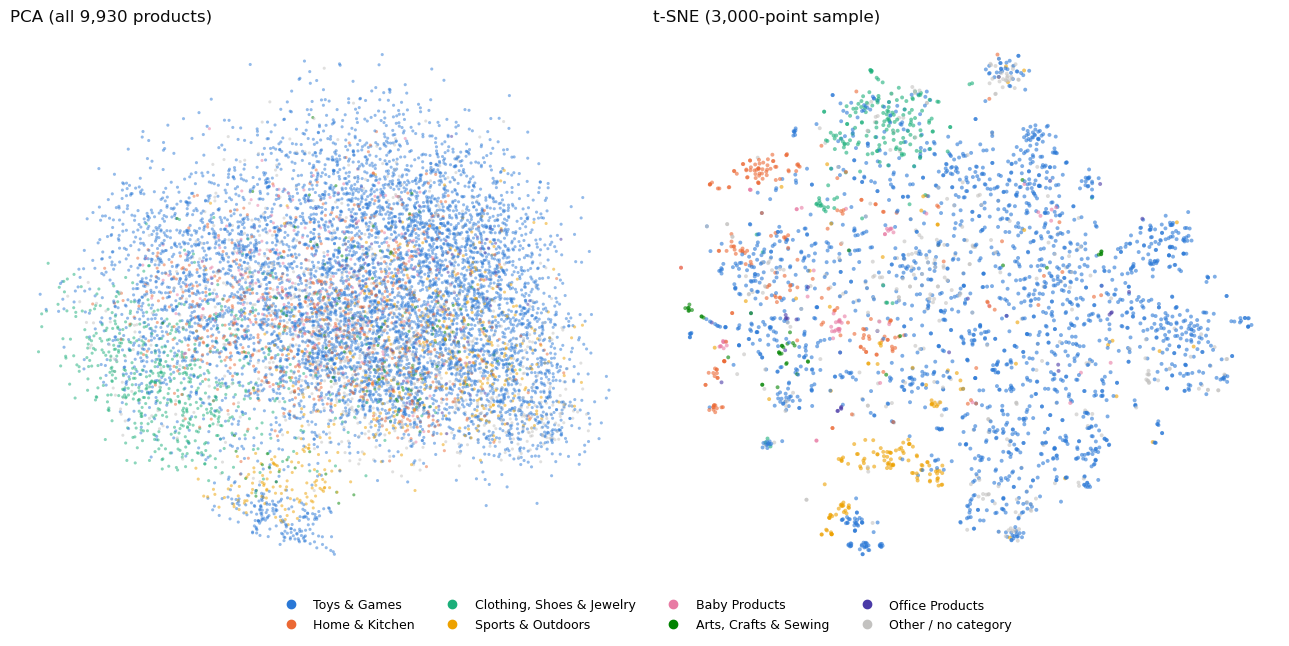

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].scatter(pca_coords[:, 0], pca_coords[:, 1], c=plot_colors, s=5, alpha=0.5, linewidths=0)
axes[0].set_title("PCA (all 9,930 products)", color=TEXT_PRIMARY, fontsize=12, loc="left")

axes[1].scatter(tsne_coords[:, 0], tsne_coords[:, 1],
                 c=plot_colors.loc[sample_idx], s=8, alpha=0.6, linewidths=0)
axes[1].set_title(f"t-SNE ({len(sample_idx):,}-point sample)", color=TEXT_PRIMARY,
                   fontsize=12, loc="left")

for ax in axes:
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

legend_handles = [plt.Line2D([0], [0], marker="o", linestyle="none", color=c, label=cat)
                   for cat, c in CAT_COLORS.items()]
legend_handles.append(plt.Line2D([0], [0], marker="o", linestyle="none", color=OTHER_COLOR,
                                  label="Other / no category"))
fig.legend(handles=legend_handles, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.08), fontsize=9)

plt.tight_layout()
plt.show()

## Summary

- **Input:** [products_clean.csv](processed/products_clean.csv) — embedding text built once
  for all 9,930 rows.
- **Embedding:** `sentence-transformers` / `all-MiniLM-L6-v2`, local, free, 384 dimensions —
  config-driven via `.env` (see [.env.example](../../.env.example)).
- **Vector store:** Chroma, one persistent directory
  (`Code/data/processed/chroma_db/`), two collections:
  - `products_home_kitchen` — the `Home & Kitchen` demo slice (706 rows)
  - `products_all` — the full cleaned catalog (all categories, 9,930 rows)
- **Metadata payload** per vector: `id, title, brand, category_top, price, price_per_unit,
  price_unit, url` — `id` is the citation `doc_id`.
- **Rebuild:** re-run this notebook — idempotent for both collections, cleans up orphaned
  on-disk segments automatically.
- Sanity-checked above against both collections with real queries.
- Embedding space visualized with PCA (full dataset) and t-SNE (3,000-point sample) —
  read the chart above for how well categories actually separate.